# Task 1: Multi-Class Benchmark Classification Pipeline (Iris)
**Datheon Machine Learning & Data Science Internship**

**Objective:** Build an end-to-end supervised classification pipeline on the Iris dataset, covering:
1. Loading the data with Pandas
2. Exploratory analysis with Seaborn pairplots
3. Feature scaling with `StandardScaler`
4. An 80/20 stratified train/test split
5. Training `LogisticRegression` and `DecisionTreeClassifier`
6. Benchmarking accuracy, precision, recall and F1-score
7. Confusion matrix heatmaps and decision boundary visualisations

## 1. Setup and imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

## 2. Load the dataset
The dataset is loaded directly from the URL provided in the task brief. If there is no internet connection, the local copy in `data/iris.csv` is used instead.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
try:
    df = pd.read_csv(DATA_URL)
    print("Loaded from URL")
except Exception:
    df = pd.read_csv("../data/iris.csv")
    print("Loaded from local copy")

print("Shape:", df.shape)
df.head()

Loaded from URL
Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Data quality checks

In [3]:
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Missing values per column:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows: 1


In [4]:
print("Class distribution:")
print(df["species"].value_counts())
df.describe()

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.000,150.000,150.000,150.000
mean,5.843,3.057,3.758,1.199
std,0.828,0.436,1.765,0.762
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


The dataset has 150 rows, 4 numeric features and 3 perfectly balanced classes (50 each), with no missing values. There is one duplicate row, which is a genuine repeated measurement in the original data, so it is kept.

## 4. Exploratory data analysis
### 4.1 Pairplot

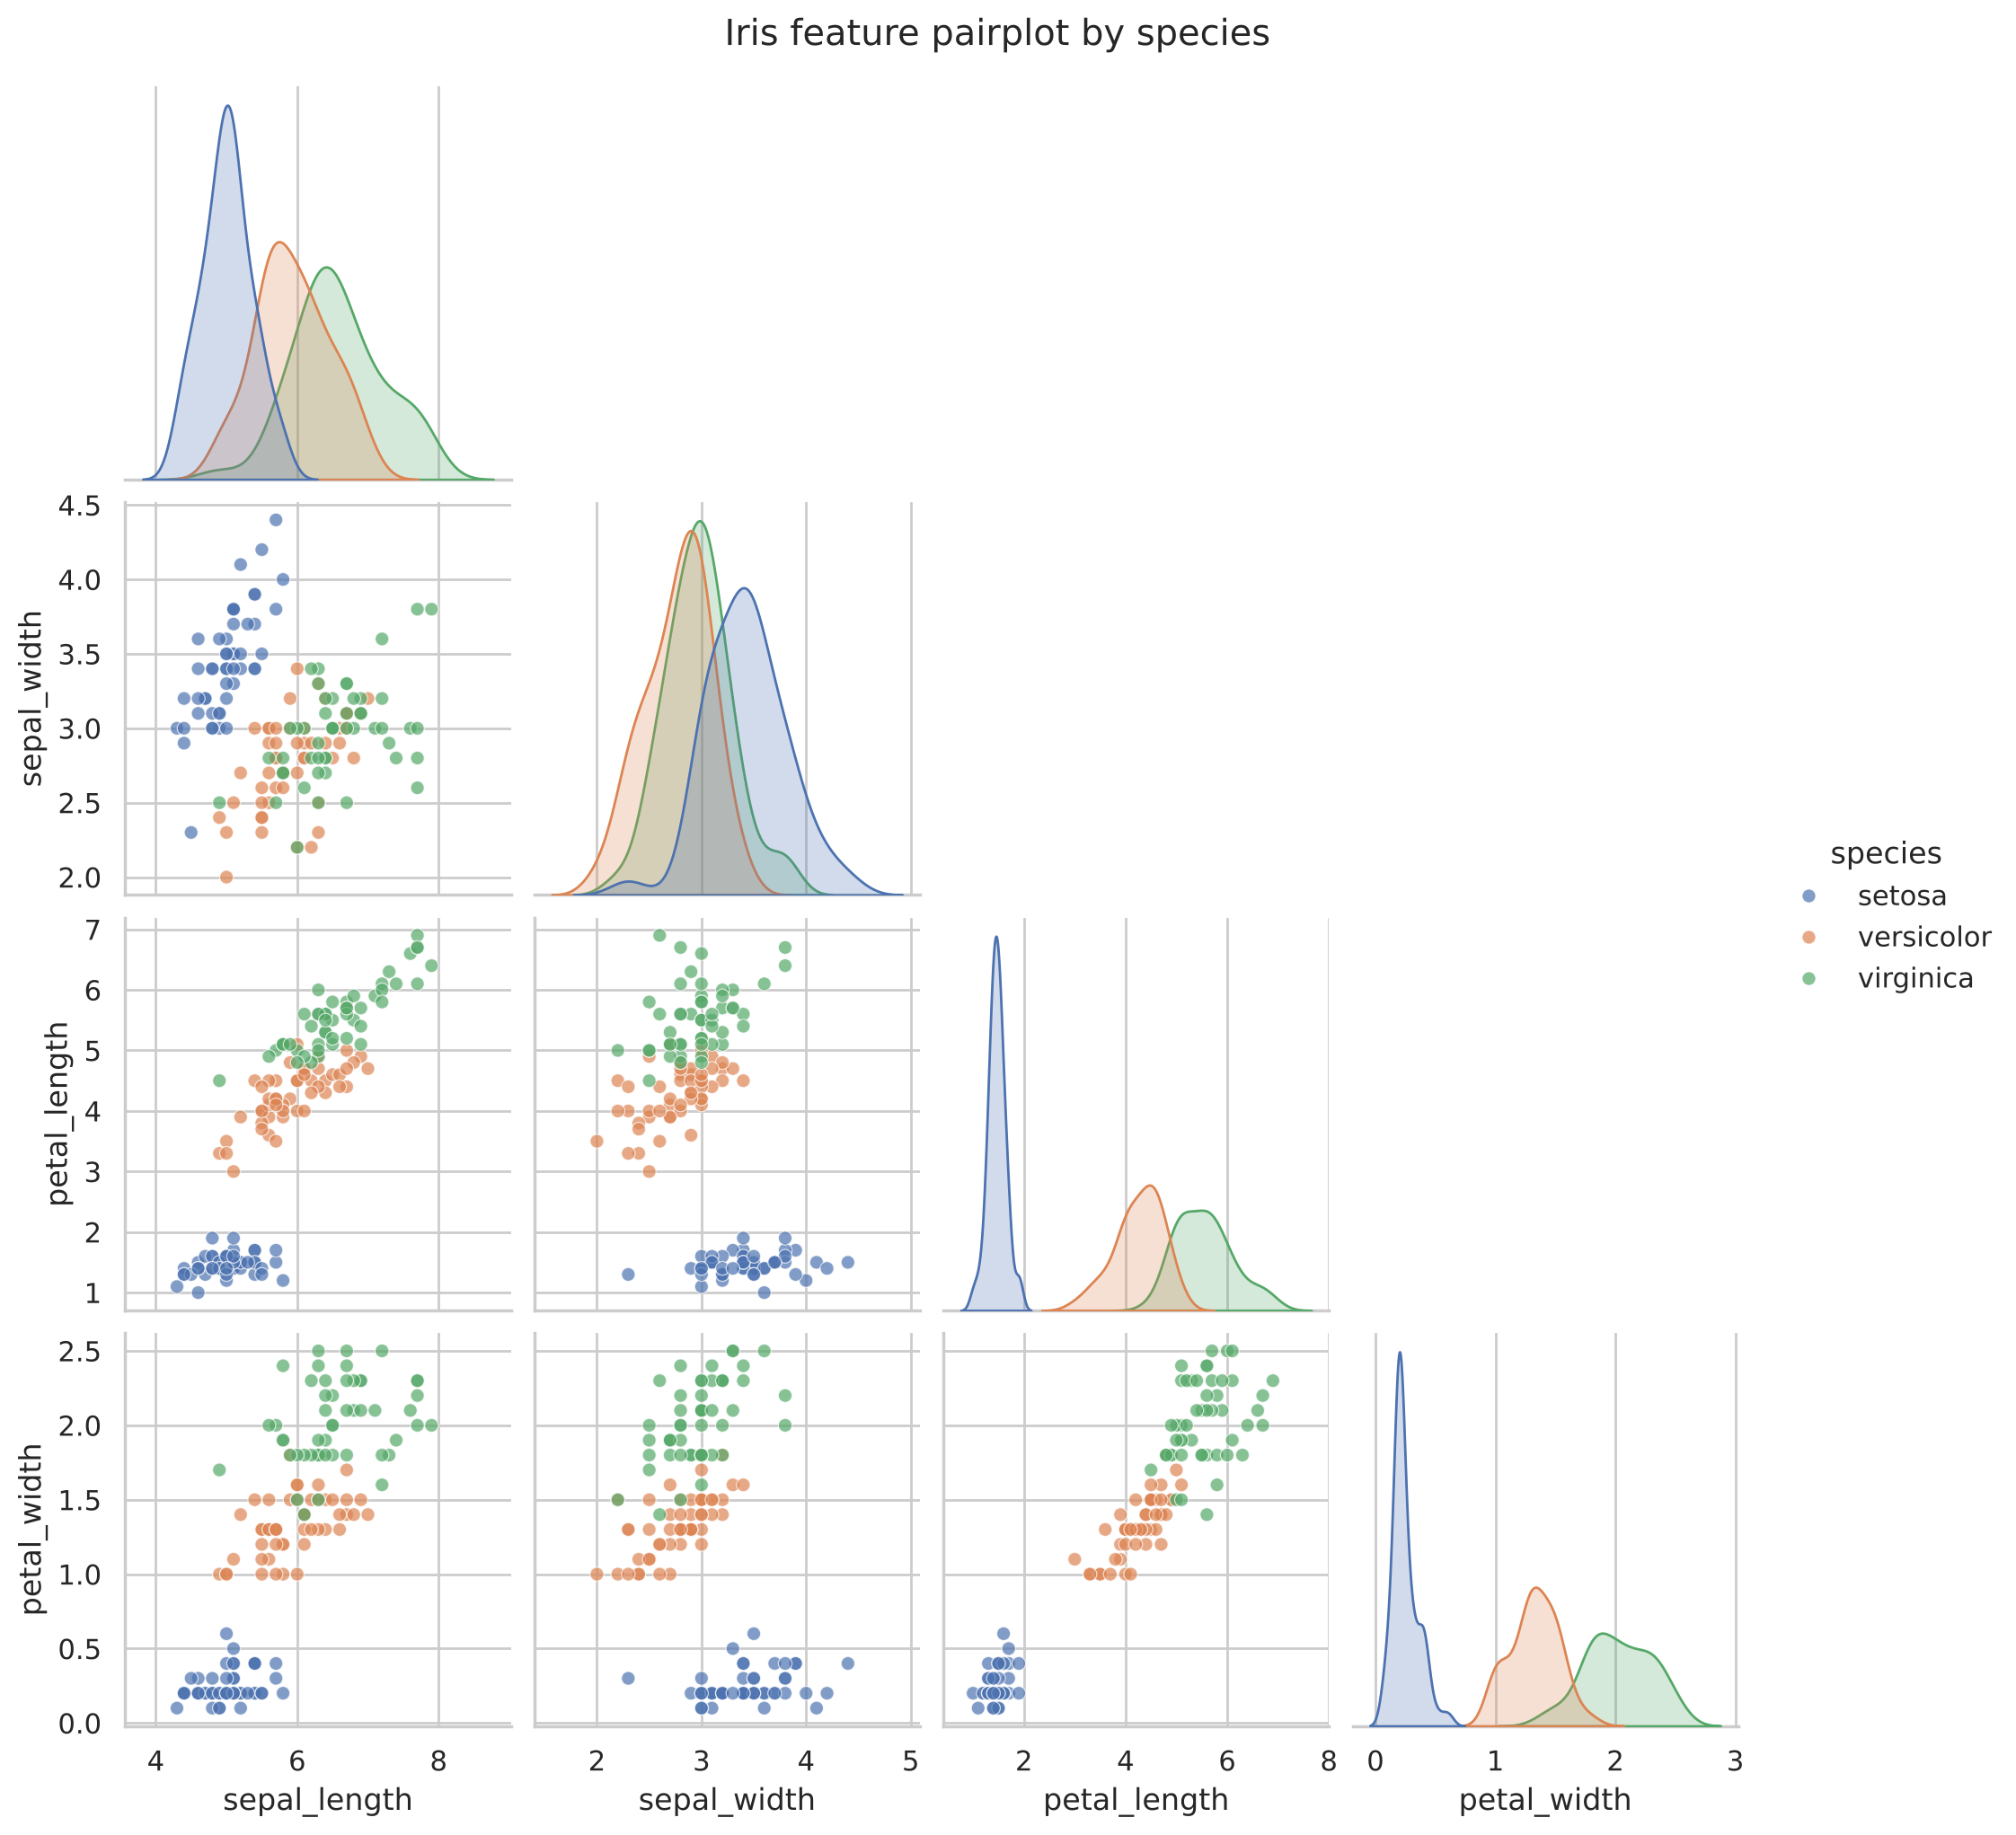

In [5]:
g = sns.pairplot(df, hue="species", corner=True, diag_kind="kde",
                 plot_kws={"alpha": 0.7, "s": 30})
g.fig.suptitle("Iris feature pairplot by species", y=1.02)
plt.show()

### 4.2 Feature distributions and correlation

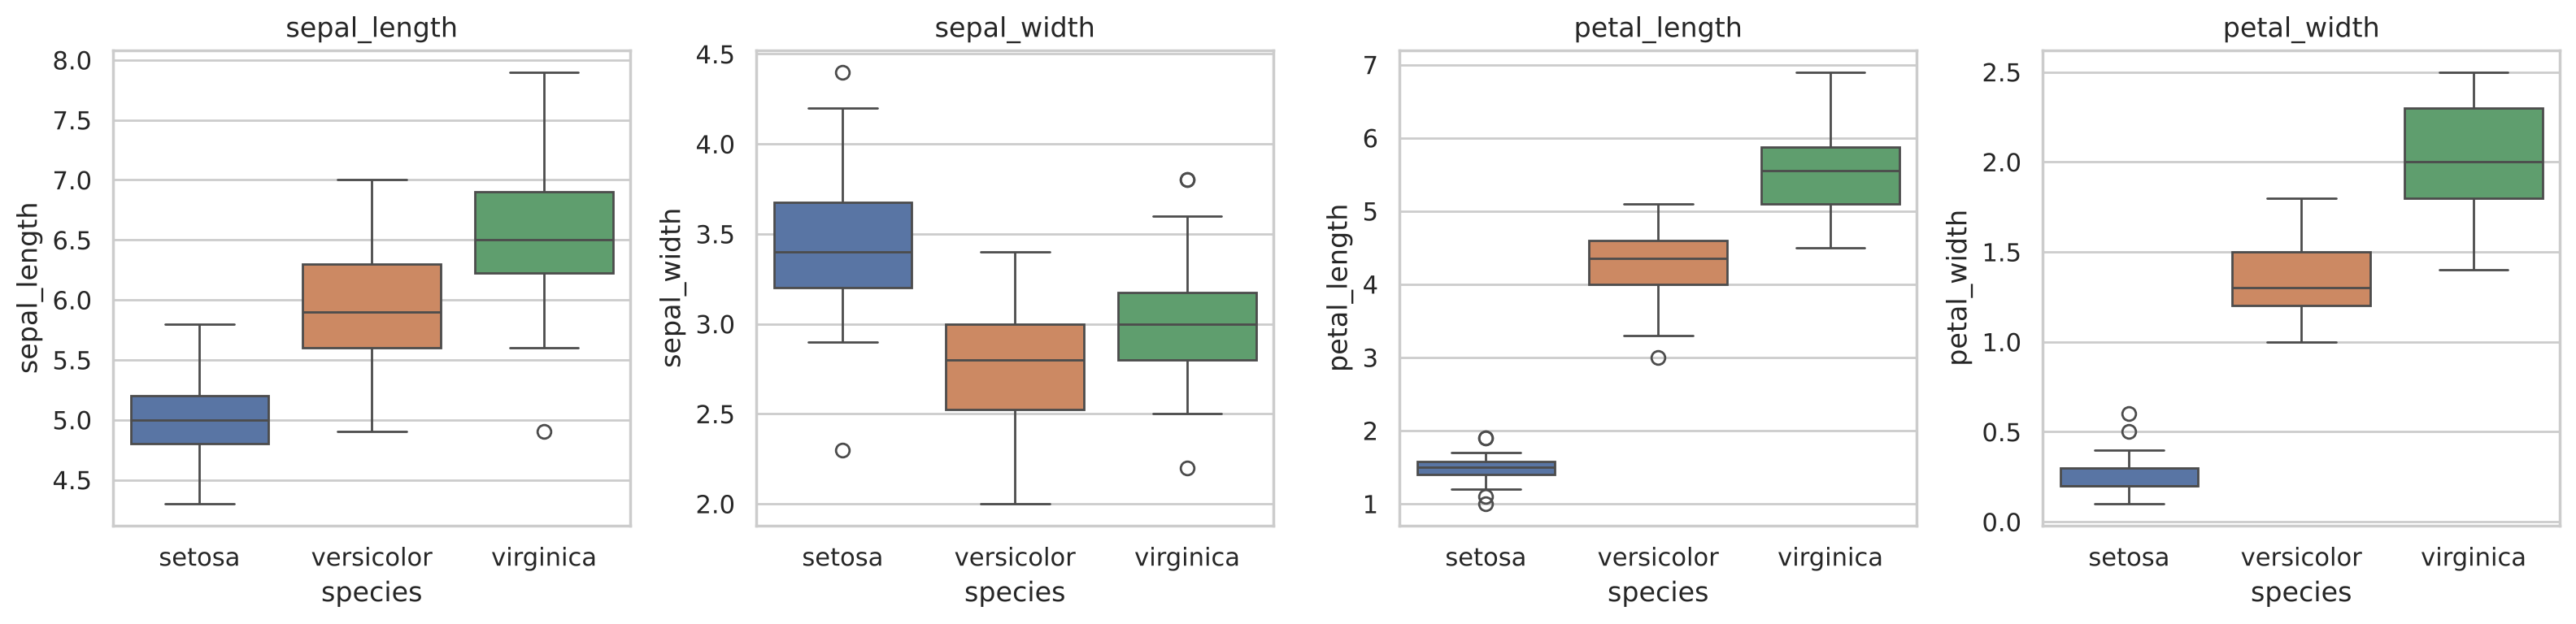

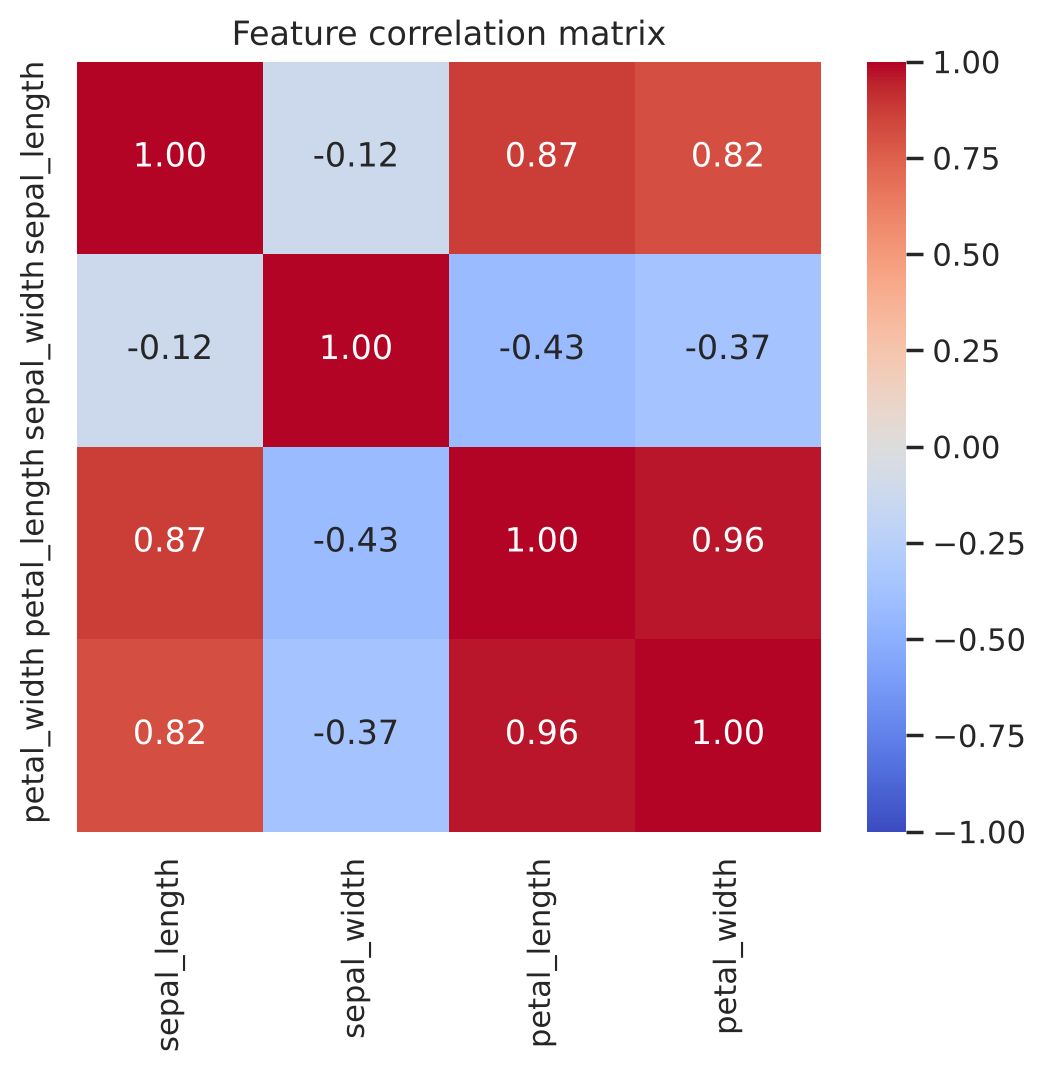

In [6]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, f in zip(axes, features):
    sns.boxplot(data=df, x="species", y=f, ax=ax, hue="species", legend=False)
    ax.set_title(f)
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Feature correlation matrix"); plt.show()

**EDA observations**
- *Setosa* is linearly separable from the other two species on petal length and petal width alone.
- *Versicolor* and *Virginica* overlap slightly, so most classification errors are expected between these two.
- Petal length and petal width are highly correlated (r ≈ 0.96) and are the most discriminative features.

## 5. Preprocessing: encoding, 80/20 split, scaling
The split is **stratified** so each class keeps the same proportion in the train and test sets. The `StandardScaler` is fitted on the **training set only** and then applied to the test set, which prevents data leakage.

In [7]:
X = df[features]
le = LabelEncoder()
y = le.fit_transform(df["species"])
class_names = le.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("Train class counts:", np.bincount(y_train), "| Test class counts:", np.bincount(y_test))
pd.DataFrame(X_train_s, columns=features).describe().loc[["mean", "std"]]

Train: (120, 4), Test: (30, 4)
Train class counts: [40 40 40] | Test class counts: [10 10 10]


,sepal_length,sepal_width,petal_length,petal_width
mean,-1.369e-16,9.992e-16,1.665e-17,1.702e-16
std,1.004e+00,1.004e+00,1.004e+00,1.004e+00


## 6. Model training

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}
preds = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    preds[name] = model.predict(X_test_s)
    print(f"{name} trained")

Logistic Regression trained
Decision Tree trained


## 7. Benchmark: accuracy, precision, recall, F1
Precision, recall and F1 are macro-averaged, so each class counts equally.

In [9]:
rows = []
for name, y_pred in preds.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
    })
results = pd.DataFrame(rows).set_index("Model")
results

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


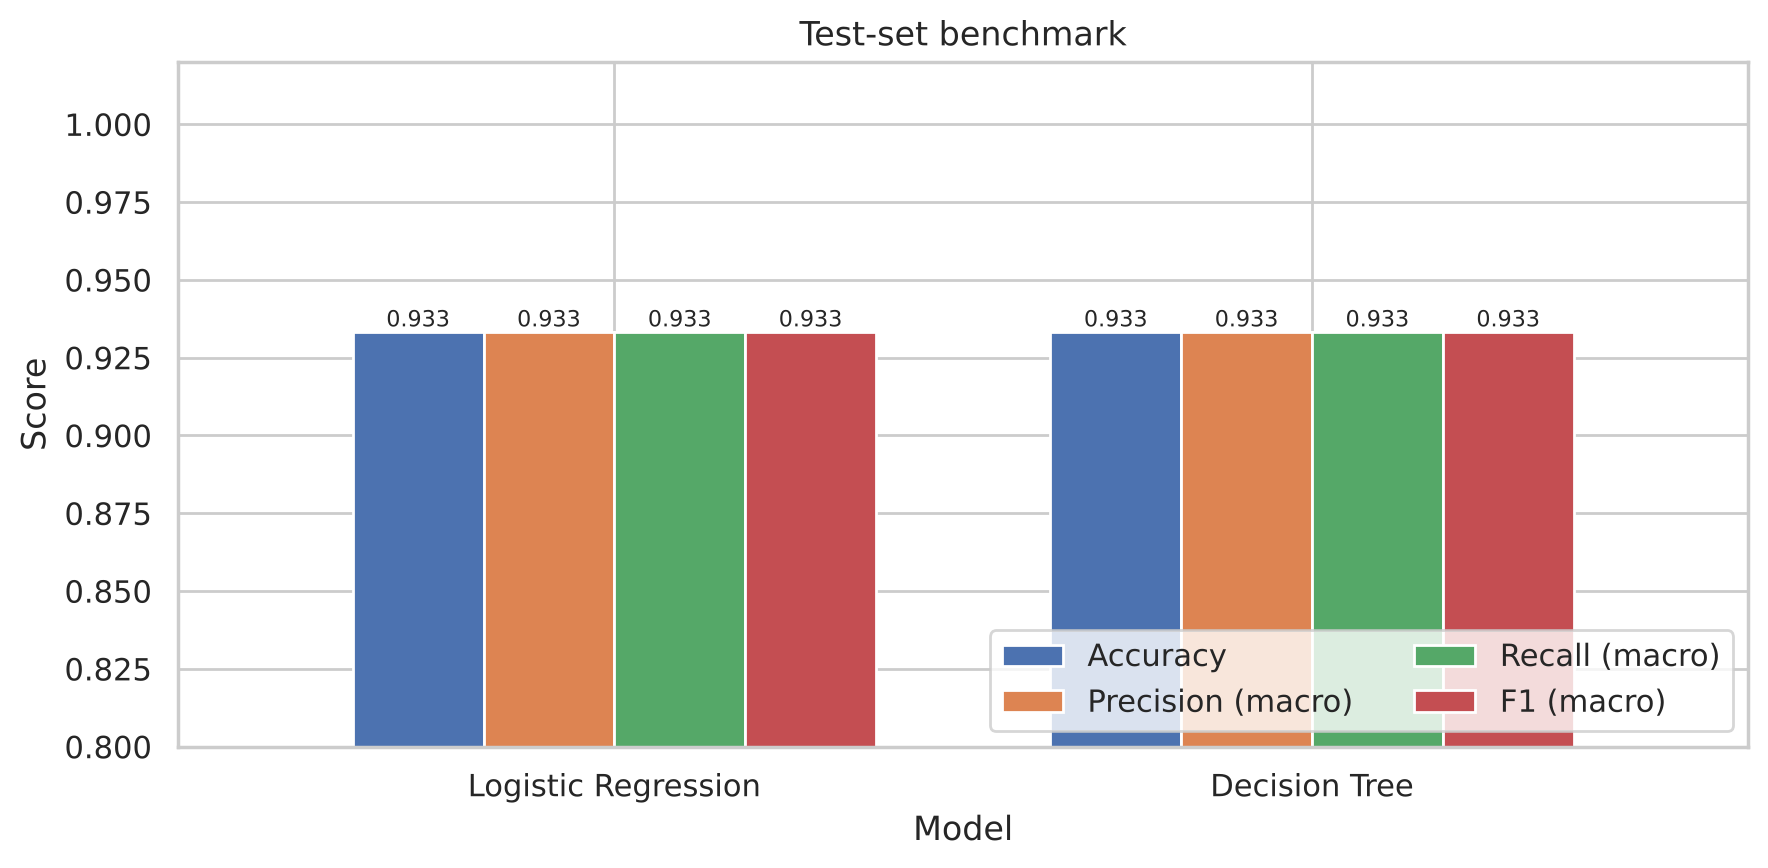

In [10]:
ax = results.plot(kind="bar", figsize=(9, 4.5), rot=0, width=0.75)
ax.set_ylim(0.8, 1.02); ax.set_ylabel("Score"); ax.set_title("Test-set benchmark")
ax.legend(loc="lower right", ncol=2)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", fontsize=8)
plt.tight_layout(); plt.show()

### 7.1 Classification reports

In [11]:
for name, y_pred in preds.items():
    print("=" * 60); print(name); print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30



### 7.2 Cross-validation (robustness check)
The test set has only 30 rows, so one or two errors change the score a lot. 5-fold stratified cross-validation on the full dataset gives a more reliable comparison. The scaler sits inside a `Pipeline` so it is refitted on each training fold.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", model)])
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="f1_macro")
    cv_rows.append({"Model": name, "CV F1 mean": scores.mean(), "CV F1 std": scores.std()})
pd.DataFrame(cv_rows).set_index("Model")

,CV F1 mean,CV F1 std
Model,,
Logistic Regression,0.953,0.045
Decision Tree,0.953,0.034


## 8. Confusion matrix heatmaps

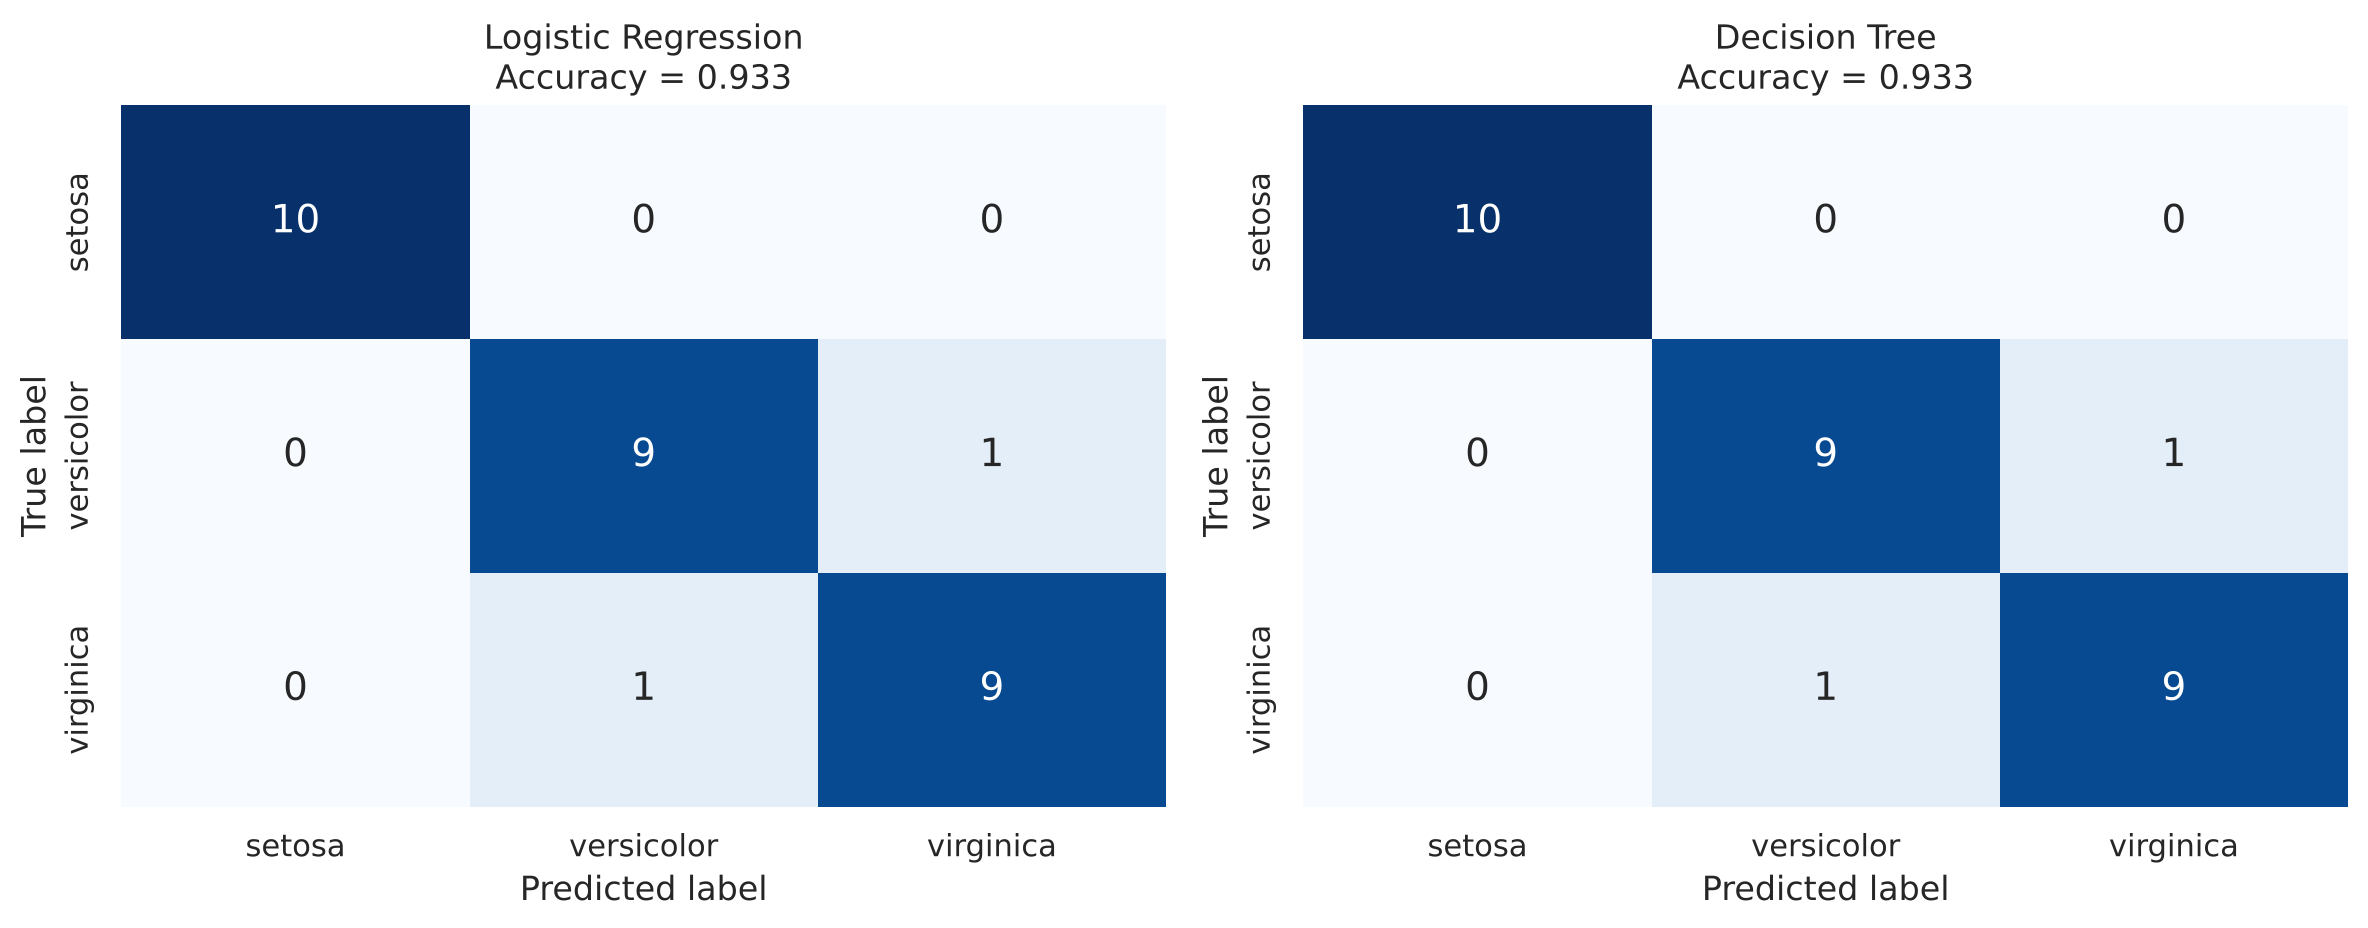

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=class_names, yticklabels=class_names, annot_kws={"size": 14})
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, y_pred):.3f}")
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
plt.tight_layout(); plt.show()

## 9. Decision boundary visualisation
Decision boundaries can only be drawn in 2D, so each model is retrained on the two most informative features, **petal length** and **petal width** (scaled). The coloured regions show which class the model predicts at every point.

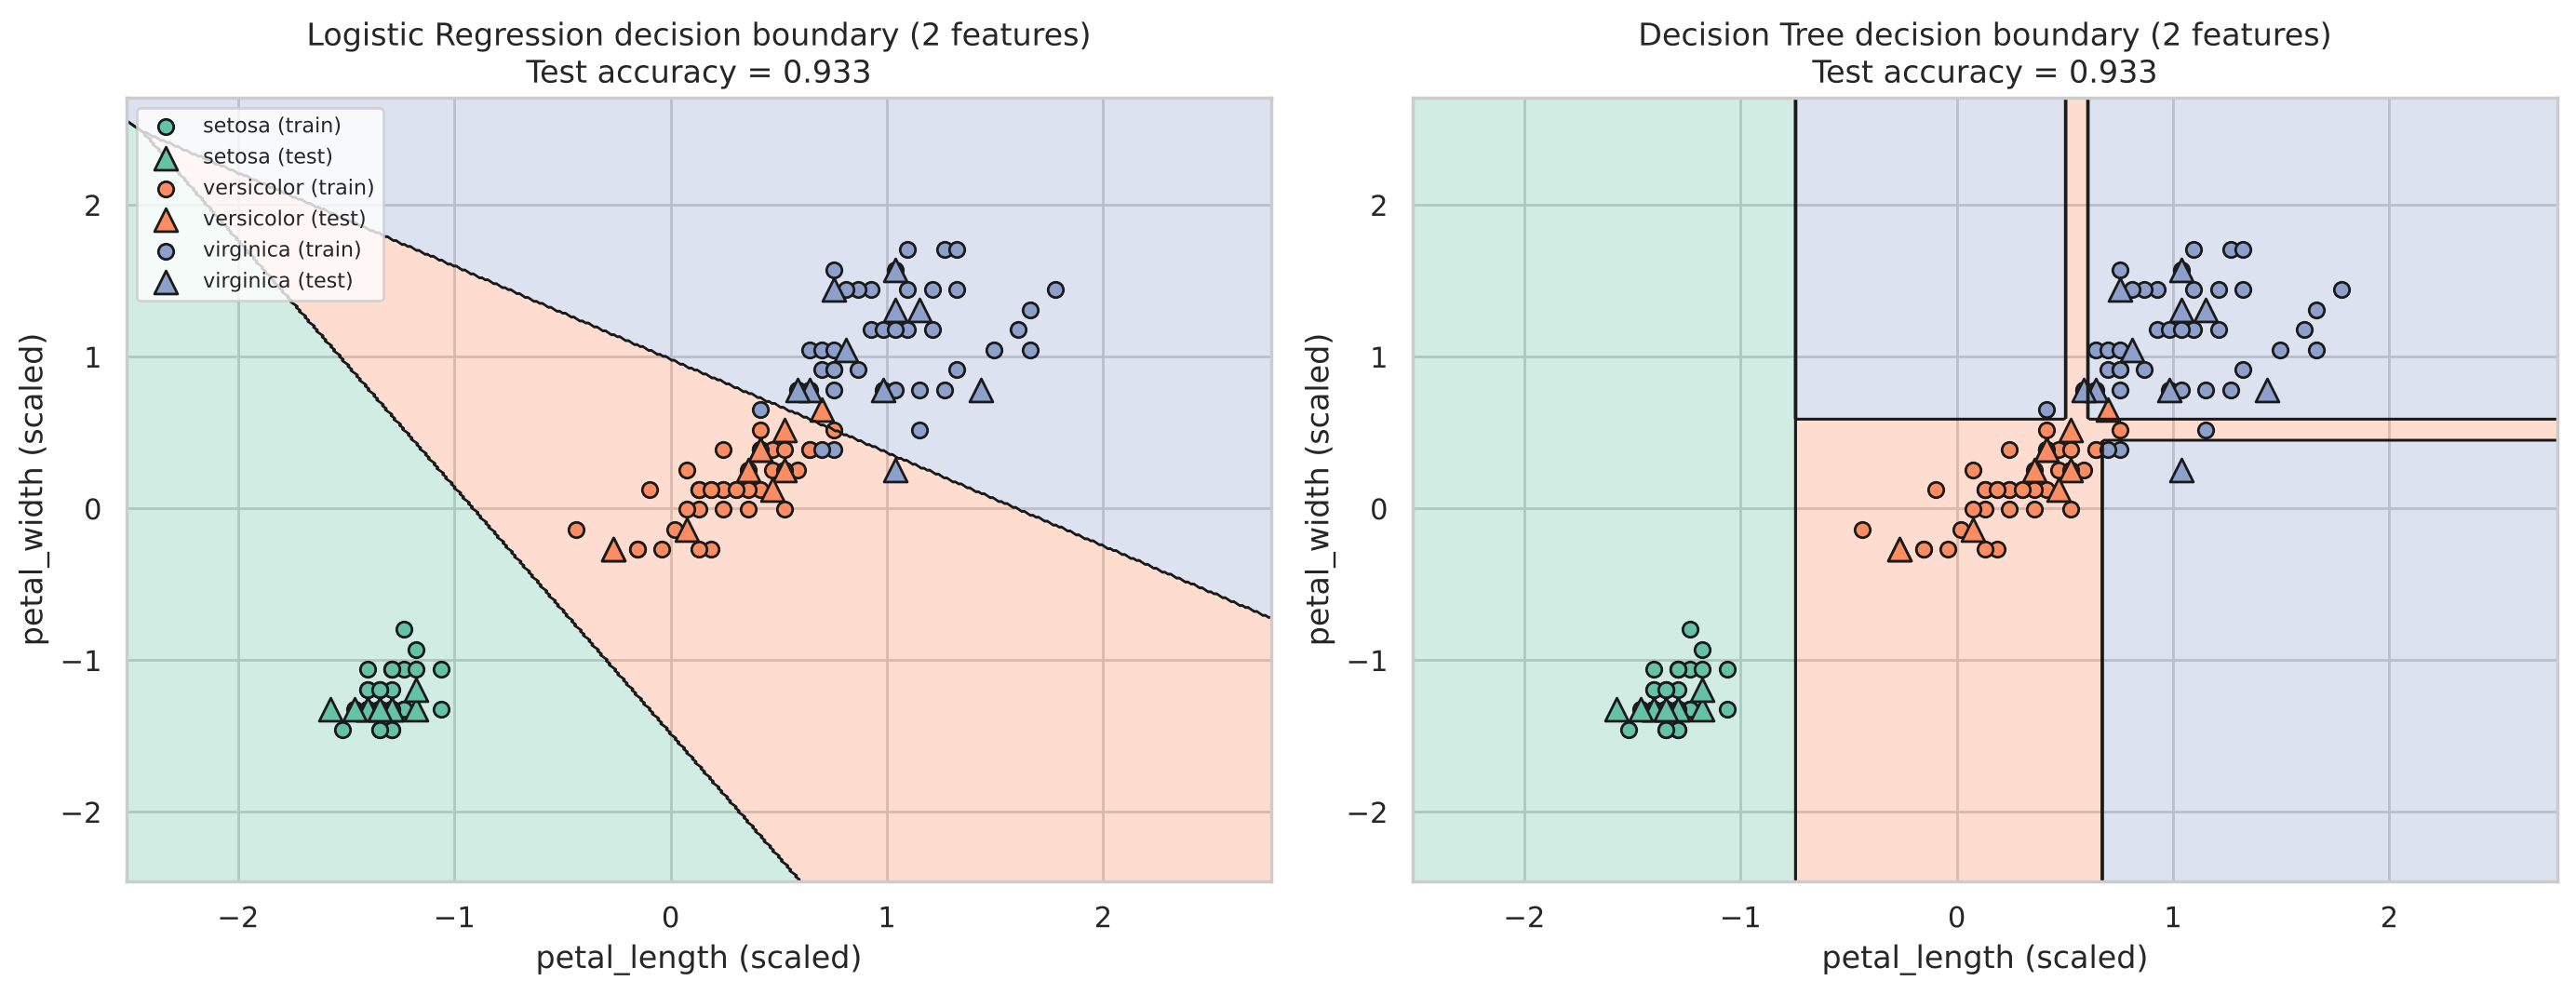

In [14]:
feat2 = ["petal_length", "petal_width"]
sc2 = StandardScaler()
X2_train = sc2.fit_transform(X_train[feat2])
X2_test = sc2.transform(X_test[feat2])

x_min, x_max = X2_train[:, 0].min() - 1, X2_train[:, 0].max() + 1
y_min, y_max = X2_train[:, 1].min() - 1, X2_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))

palette = sns.color_palette("Set2", 3)
from matplotlib.colors import ListedColormap
cmap = ListedColormap(palette)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, base) in zip(axes, models.items()):
    m = base.__class__(**base.get_params()).fit(X2_train, y_train)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap)
    ax.contour(xx, yy, Z, colors="k", linewidths=0.5)
    for i, cls in enumerate(class_names):
        ax.scatter(X2_train[y_train == i, 0], X2_train[y_train == i, 1], color=palette[i],
                   edgecolor="k", s=35, label=f"{cls} (train)")
        ax.scatter(X2_test[y_test == i, 0], X2_test[y_test == i, 1], color=palette[i],
                   edgecolor="k", marker="^", s=80, label=f"{cls} (test)")
    acc = accuracy_score(y_test, m.predict(X2_test))
    ax.set_title(f"{name} decision boundary (2 features)\nTest accuracy = {acc:.3f}")
    ax.set_xlabel("petal_length (scaled)"); ax.set_ylabel("petal_width (scaled)")
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

The Logistic Regression produces smooth linear boundaries, while the Decision Tree produces axis-aligned rectangular regions, which reflects how each algorithm splits the feature space.

## 10. Model interpretation

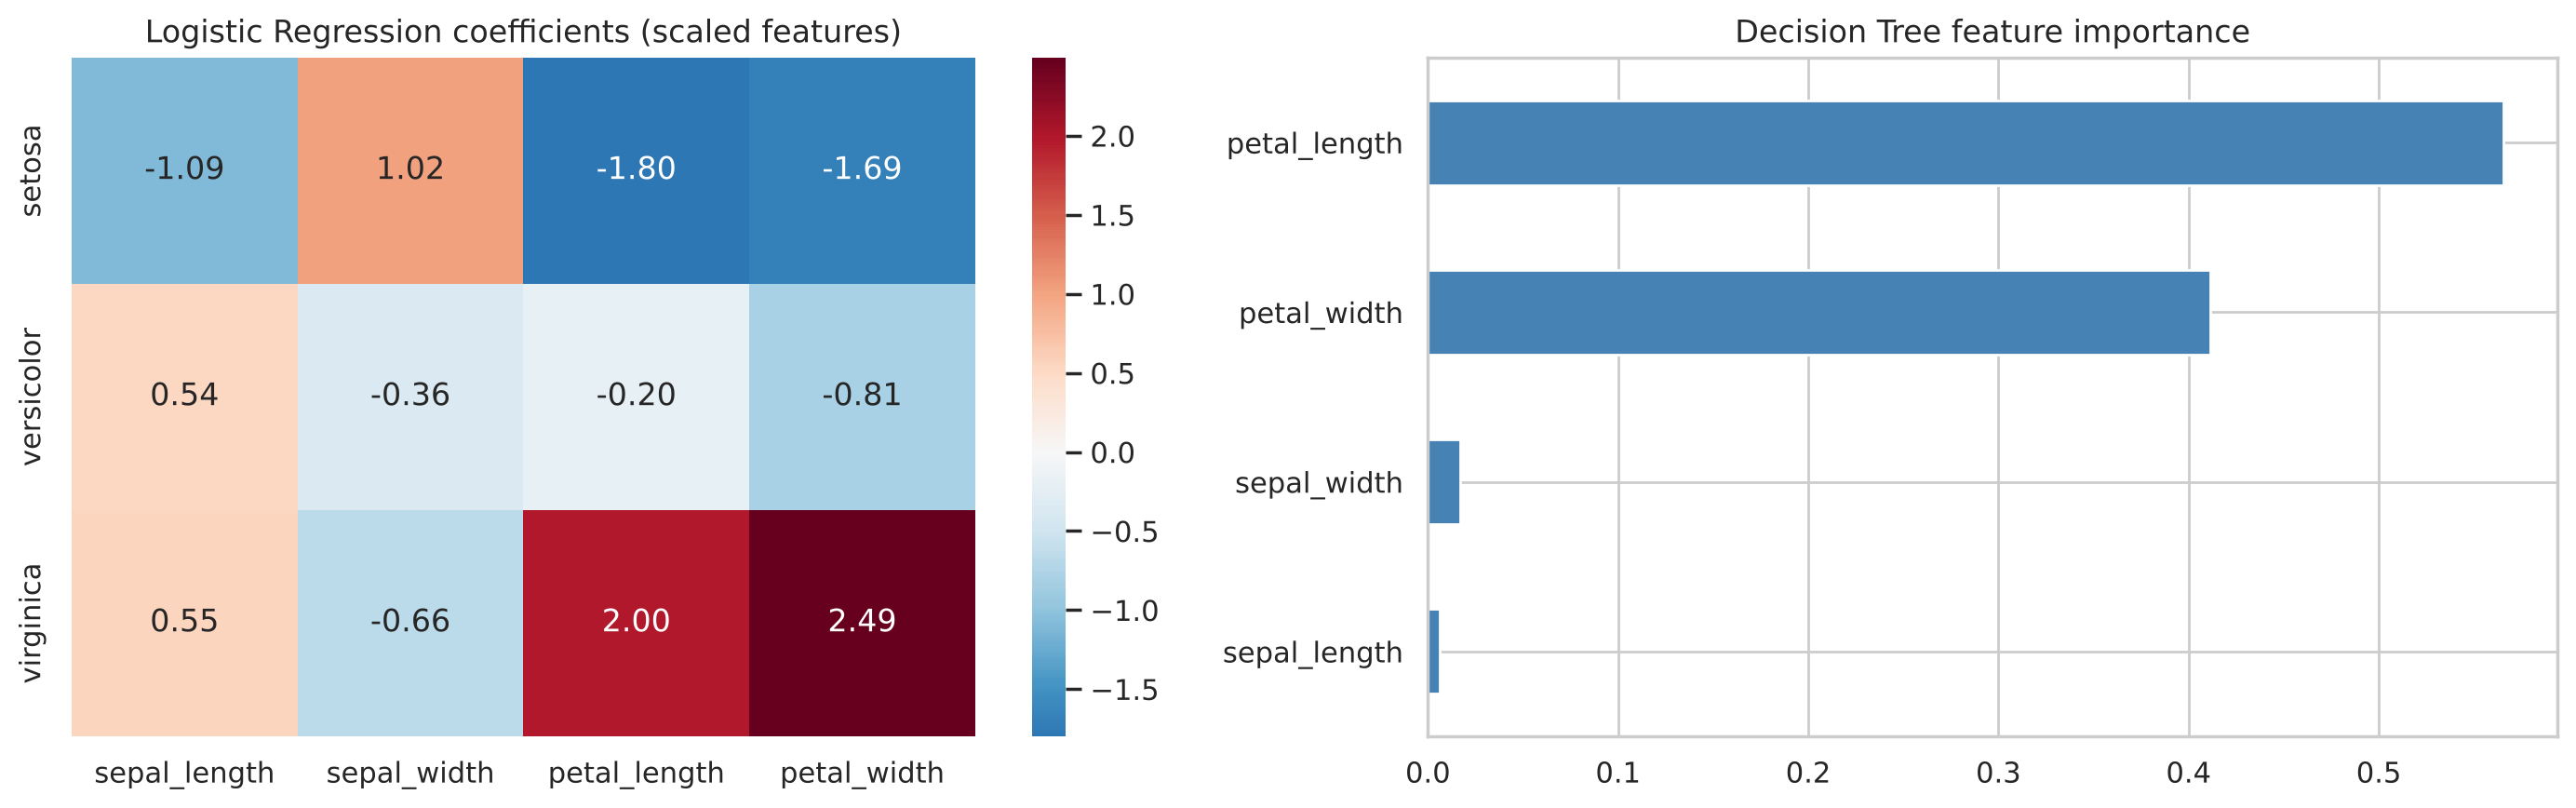

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
coef = pd.DataFrame(models["Logistic Regression"].coef_, columns=features, index=class_names)
sns.heatmap(coef, annot=True, cmap="RdBu_r", center=0, fmt=".2f", ax=axes[0])
axes[0].set_title("Logistic Regression coefficients (scaled features)")

imp = pd.Series(models["Decision Tree"].feature_importances_, index=features).sort_values()
imp.plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Decision Tree feature importance")
plt.tight_layout(); plt.show()

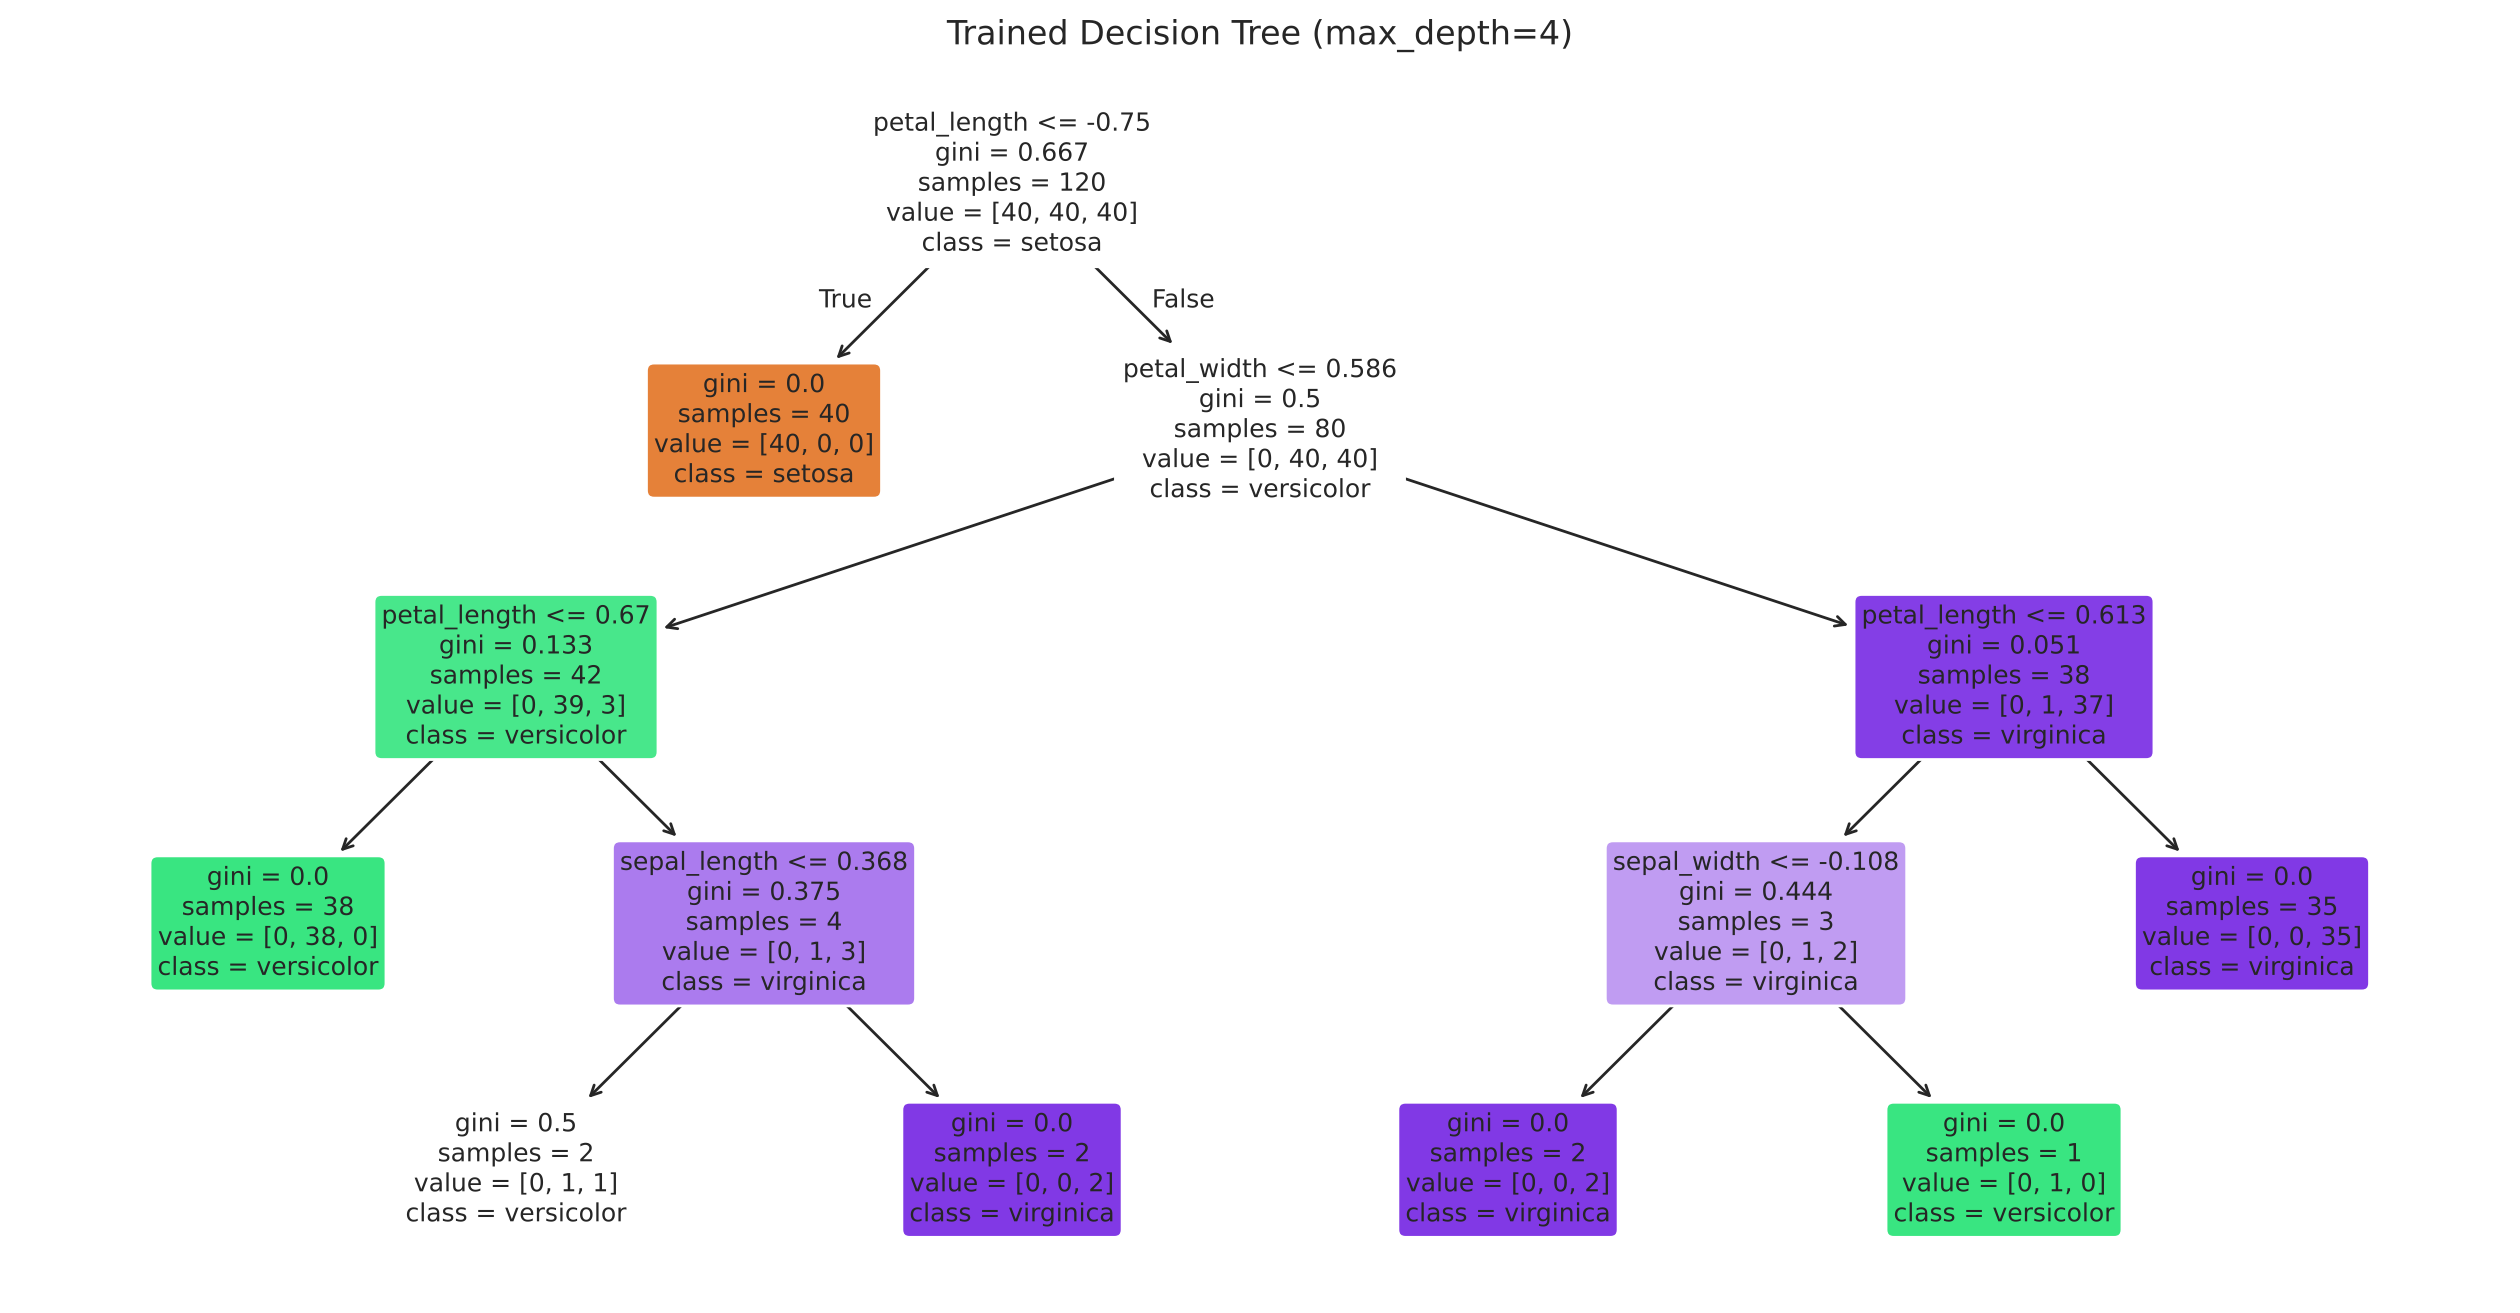

In [16]:
plt.figure(figsize=(16, 8))
plot_tree(models["Decision Tree"], feature_names=features, class_names=list(class_names),
          filled=True, rounded=True, fontsize=9)
plt.title("Trained Decision Tree (max_depth=4)"); plt.show()

## 11. Conclusions

In [17]:
print(results.round(3).to_string())
top = results["F1 (macro)"].max()
best = results.index[np.isclose(results["F1 (macro)"], top)].tolist()
print(f"\nBest test-set macro F1 = {top:.3f}: {' and '.join(best)}")

                     Accuracy  Precision (macro)  Recall (macro)  F1 (macro)
Model                                                                       
Logistic Regression     0.933              0.933           0.933       0.933
Decision Tree           0.933              0.933           0.933       0.933

Best test-set macro F1 = 0.933: Logistic Regression and Decision Tree


**Summary of findings**
- Both models reach **93.3% accuracy** and **0.933 macro F1** on the held-out test set (28 of 30 correct), and both score **0.953 mean F1** in 5-fold cross-validation.
- *Setosa* is always predicted correctly. The few errors are between *Versicolor* and *Virginica*, exactly where the EDA showed the classes overlap.
- Performance is effectively tied, so the choice comes down to other factors. **Logistic Regression** gives smooth, stable linear boundaries and calibrated probabilities. The **Decision Tree** is easier to explain as simple if/else rules and had slightly lower variance across CV folds (std 0.034 vs 0.045), but its rectangular boundaries can be sensitive to the training sample.
- Petal measurements dominate both models, which matches the pairplot and correlation analysis.

**Possible next steps:** hyperparameter tuning with `GridSearchCV`, trying SVM or Random Forest, and repeating the pipeline on the Wine dataset.